正在运行 300 次模拟，请稍候...

无缝推断 I 类错误率 (FWER) 模拟结果：
1. 未校正 (alpha=0.05)      : 12.33%  <-- 膨胀
2. Bonferroni (alpha=0.0125): 3.33%  <-- 控制良好
图像已保存至 outputs/figures/fwer_simulation.png


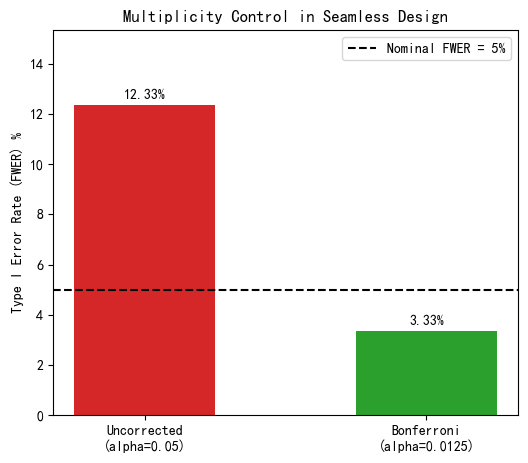

In [2]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# 设置中文字体，防止图表中文显示为方块
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

def simulate_fwer(n_sim, alpha_adj):
    """模拟无缝试验，验证 I 类错误率 (FWER)"""
    rng = np.random.default_rng(1128)
    sd = 0.5
    placebo_mean = 1.31
    n_stage1, n_stage2 = 120, 285
    rejections = 0
    
    for _ in range(n_sim):
        # 阶段1：4个剂量 + 安慰剂
        stage1_doses = [rng.normal(placebo_mean, sd, n_stage1) for _ in range(4)]
        stage1_placebo = rng.normal(placebo_mean, sd, n_stage1)
        
        # 选均值最高的两个
        means = [d.mean() for d in stage1_doses]
        selected_idx = np.argsort(means)[-2:] 
        
        # 阶段2：继续入组
        stage2_selected = [rng.normal(placebo_mean, sd, n_stage2) for _ in selected_idx]
        stage2_placebo = rng.normal(placebo_mean, sd, n_stage2)
        
        # 合并阶段（无缝推断）
        combined_placebo = np.concatenate([stage1_placebo, stage2_placebo])
        
        # 终末检验
        for i, idx in enumerate(selected_idx):
            merged = np.concatenate([stage1_doses[idx], stage2_selected[i]])
            t_stat, p_two = stats.ttest_ind(merged, combined_placebo, equal_var=False)
            if (p_two / 2) < alpha_adj and merged.mean() > combined_placebo.mean():
                rejections += 1
                break 
                
    return rejections / n_sim

# ===== 运行 300 次 =====
n_simulations = 300
print(f"正在运行 {n_simulations} 次模拟，请稍候...")

fwer_uncorrected = simulate_fwer(n_simulations, 0.05)
fwer_corrected = simulate_fwer(n_simulations, 0.05 / 4)

print("\n" + "="*50)
print("无缝推断 I 类错误率 (FWER) 模拟结果：")
print(f"1. 未校正 (alpha=0.05)      : {fwer_uncorrected*100:.2f}%  <-- 膨胀")
print(f"2. Bonferroni (alpha=0.0125): {fwer_corrected*100:.2f}%  <-- 控制良好")
print("="*50)

# ===== 画图并保存到 outputs/figures =====
plt.figure(figsize=(6, 5))
bars = plt.bar(['Uncorrected\n(alpha=0.05)', 'Bonferroni\n(alpha=0.0125)'], 
               [fwer_uncorrected*100, fwer_corrected*100], 
               color=['#d62728', '#2ca02c'], width=0.5)

plt.axhline(5, color='black', linestyle='--', label='Nominal FWER = 5%')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.2, f'{yval:.2f}%', ha='center', va='bottom')

plt.ylabel('Type I Error Rate (FWER) %')
plt.title('Multiplicity Control in Seamless Design')
plt.ylim(0, max(fwer_uncorrected, fwer_corrected)*100 + 3)
plt.legend()

# 保存图片
plt.savefig('outputs/figures/fwer_simulation.png', dpi=150, bbox_inches='tight')
print("图像已保存至 outputs/figures/fwer_simulation.png")
plt.show()